In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
def deseasonalize(data_arr):
    #compute monthly mean
    seasonal_mean = data_arr.groupby('time.month').mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.month') - seasonal_mean
    return deseasonalized_data_arr

In [3]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, 0
plon = (lon_max + lon_min)/2
plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

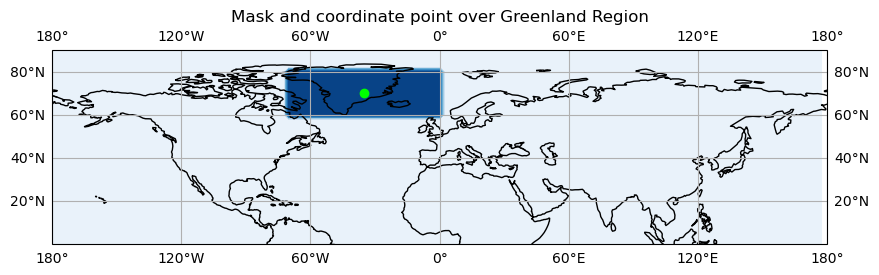

In [4]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())
plt.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask and coordinate point over Greenland Region')

# Show the plot
plt.show()

In [5]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')
ds_filt_MIX = xr.open_dataset('ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc')

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [6]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries/
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dic_for_filtering_MIX = np.load('ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dics =(dic_for_filtering_DAV,dic_for_filtering_GHA,dic_for_filtering_MIX)

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries


In [7]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
MIX_filt = ds_filt_MIX['MIX_tracked']
np_array_GHA = GHA_filt.values
np_array_DAV = DAV_filt.values
np_array_MIX = MIX_filt.values
np_arrays = (np_array_DAV,np_array_GHA,np_array_MIX)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
ilon = list(ds_filt_DAV.lon.values).index(ds_filt_DAV.sel(lon=plon, method='nearest').lon)
ilat = list(ds_filt_DAV.lat.values).index(ds_filt_DAV.sel(lat=plat, method='nearest').lat)
months = ['06','07','08']

# FIGURE 1 
## Trajectories

In [8]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
labels = [[],[],[]]
timings = [[],[],[]]
min_pers = (3,3,3)
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    if t > len(times.values)-5:
        break
    if month in months:
        for i,arr in enumerate(np_arrays):
            if arr[t,ilat,ilon] != 0:
                label = arr[t,ilat,ilon]
                check_cond = []
                for k in range(min_pers[i]):
                    check_cond.append(arr[t+k,ilat,ilon]==label)
                if label not in labels[i] and np.all(check_cond):
                    labels[i].append(label)
                    timings[i].append(t)

30677it [00:09, 3078.70it/s]


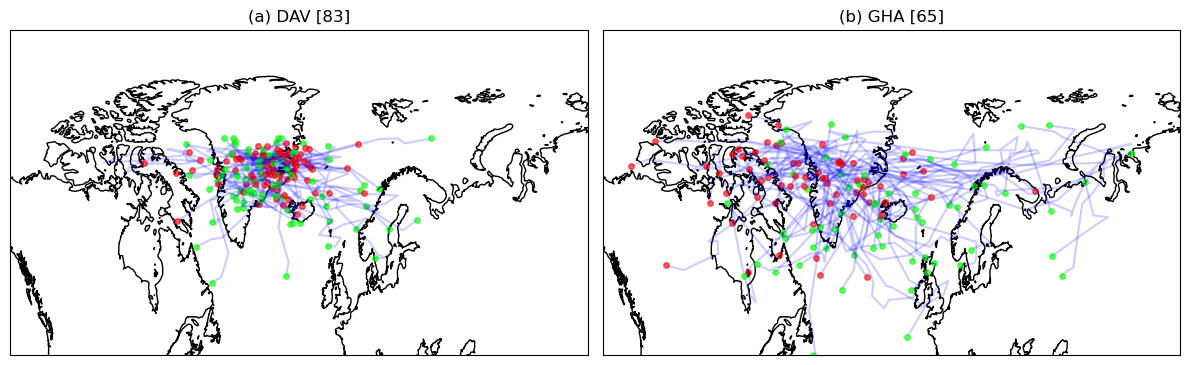

In [9]:
'''
TRAJECTORY PLOT
'''
fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), subplot_kw={'projection': ccrs.PlateCarree()})
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
titles = ['(a) DAV [' + str(len(labels[0])) + ']','(b) GHA [' + str(len(labels[1])) + ']','MIX [' + str(len(labels[2])) + ']']
datacrs = ccrs.PlateCarree()
extent =[-140,+100,45,90]
#extent =[-180,+180,45,90]

for j in range(2):
    axarr[j].set_extent(extent, datacrs)
    axarr[j].coastlines()
    axarr[j].set_aspect(3)
    axarr[j].set_title(titles[j])
    for l,label in enumerate(labels[j]):
        #print(label)
        cm = axarr[j].plot(dics[j][label]['track'][1],dics[j][label]['track'][0],color='blue',alpha=0.2,transform=datacrs)
        #plot the ending center of mass position
        end = axarr[j].plot(dics[j][label]['track'][1][-1],dics[j][label]['track'][0][-1],'o', markersize=4,color='r',alpha=0.6,transform=datacrs)
        #plot the starting center of mass position
        start = axarr[j].plot(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],'o', markersize=4,color='lime',alpha=0.6,transform=datacrs)
        #text = axarr[j].text(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],str(label),transform=datacrs)

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure1.pdf')
    

# FIGURE 2

## Composites

In [10]:
#open composite datasets
#ds_geop = xr.open_dataset('../../geop/ERA5_northem_2.5x2.5_zg500_daily_1940-2023_deseasonalized.nc')
ds_temp = xr.open_dataset('../../temperature/ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')
ds_IVT = xr.open_dataset('../../IVT/ERA5_IVT_northem_daily_2.5x2.5_1940-2023_deseasonalized.nc')

In [11]:
zg = ds_filt_DAV['zg']/9.81
t2m = deseasonalize(ds_temp['t2m'])
IVT = deseasonalize(ds_IVT['IVT'])

In [12]:
#bootstrap function for statistical significance
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

In [13]:
labels_retrograding = [[],[],[]]
labels_upstream = [[],[],[]]
zg_retrograding = [[],[],[]]
zg_upstream = [[],[],[]]
t2m_retrograding = [[],[],[]]
t2m_upstream = [[],[],[]]
IVT_retrograding = [[],[],[]]
IVT_upstream = [[],[],[]]
#populating the lists
for i,arr in enumerate(np_arrays):
    for j,label in tqdm(enumerate(labels[i])):
        #print(label)
        previous_coords = []
        for k in range(3):
            if (timings[i][j]-dics[i][label]['time'] - k) >= 0:
                previous_coords.append(dics[i][label]['track'][1][timings[i][j]-dics[i][label]['time'] - k])
        #if np.sum(dics[i][label]['track'][1])/dics[i][label]['persistence'] - plon > 0:
        if np.mean(previous_coords) - plon > 0:
        #if dics[i][label]['track'][1][0] > plon:
        #if dics[i][label]['track'][1][-1] < plon:
            labels_retrograding[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if arr[t,ilat,ilon] == label:
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        zg_retrograding[i].append(zg.loc[date,:,:].values)
                        t2m_retrograding[i].append(t2m.loc[date,:,:].values)
                        IVT_retrograding[i].append(IVT.loc[date,:,:].values)
        #if np.sum(dics[i][label]['track'][1])/dics[i][label]['persistence'] - plon <= 0:
        if np.mean(previous_coords) - plon <= 0:
        #if dics[i][label]['track'][1][0] <= plon:
        #if dics[i][label]['track'][1][-1] >= plon:
            labels_upstream[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']):
                if arr[t,ilat,ilon] == label:
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        zg_upstream[i].append(zg.loc[date,:,:].values)
                        t2m_upstream[i].append(t2m.loc[date,:,:].values)
                        IVT_upstream[i].append(IVT.loc[date,:,:].values)
#computing the composites
zg_mean = zg.mean('time')
t2m_mean = t2m.mean('time')
IVT_mean = IVT.mean('time')
zg_retrograding_comp = [0,0,0]
zg_retrograding_t_st = [0,0,0]
zg_upstream_comp = [0,0,0]
zg_upstream_t_st = [0,0,0]
t2m_retrograding_comp = [0,0,0]
t2m_retrograding_t_st = [0,0,0]
t2m_upstream_comp = [0,0,0]
t2m_upstream_t_st = [0,0,0]
IVT_retrograding_comp = [0,0,0]
IVT_retrograding_t_st = [0,0,0]
IVT_upstream_comp = [0,0,0]
IVT_upstream_t_st = [0,0,0]

#print(abs(zg_retrograding_comp[0]/Bootstrap(zg-zg_mean,len(zg_retrograding[0]),100)) > 2)

for i,var in enumerate(('DAV','GHA','MIX')):
    print(var)
    
    'ZG'
    zg_retrograding_comp[i] = sum(zg_retrograding[i])/len(zg_retrograding[i])
    zg_upstream_comp[i] = sum(zg_upstream[i])/len(zg_upstream[i])

    't2m'
    t2m_retrograding_comp[i] = sum(t2m_retrograding[i])/len(t2m_retrograding[i]) - t2m_mean
    t2m_retrograding_t_st[i] = abs(t2m_retrograding_comp[i]/Bootstrap(t2m-t2m_mean,len(t2m_retrograding[i]),100)) > 2
    t2m_upstream_comp[i] = sum(t2m_upstream[i])/len(t2m_upstream[i]) - t2m_mean
    t2m_upstream_t_st[i] = abs(t2m_upstream_comp[i]/Bootstrap(t2m-t2m_mean,len(t2m_upstream[i]),100)) > 2
    
    'IVT'
    IVT_retrograding_comp[i] = sum(IVT_retrograding[i])/len(IVT_retrograding[i]) - IVT_mean
    IVT_retrograding_t_st[i] = abs(IVT_retrograding_comp[i]/Bootstrap(IVT-IVT_mean,len(IVT_retrograding[i]),100)) > 2
    IVT_upstream_comp[i] = sum(IVT_upstream[i])/len(IVT_upstream[i]) - IVT_mean
    IVT_upstream_t_st[i] = abs(IVT_upstream_comp[i]/Bootstrap(IVT-IVT_mean,len(IVT_upstream[i]),100)) > 2


83it [00:00, 168.67it/s]
65it [00:00, 170.29it/s]
63it [00:00, 172.08it/s]


DAV


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 114.10it/s]


GHA


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 171.39it/s]


MIX


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 148.86it/s]


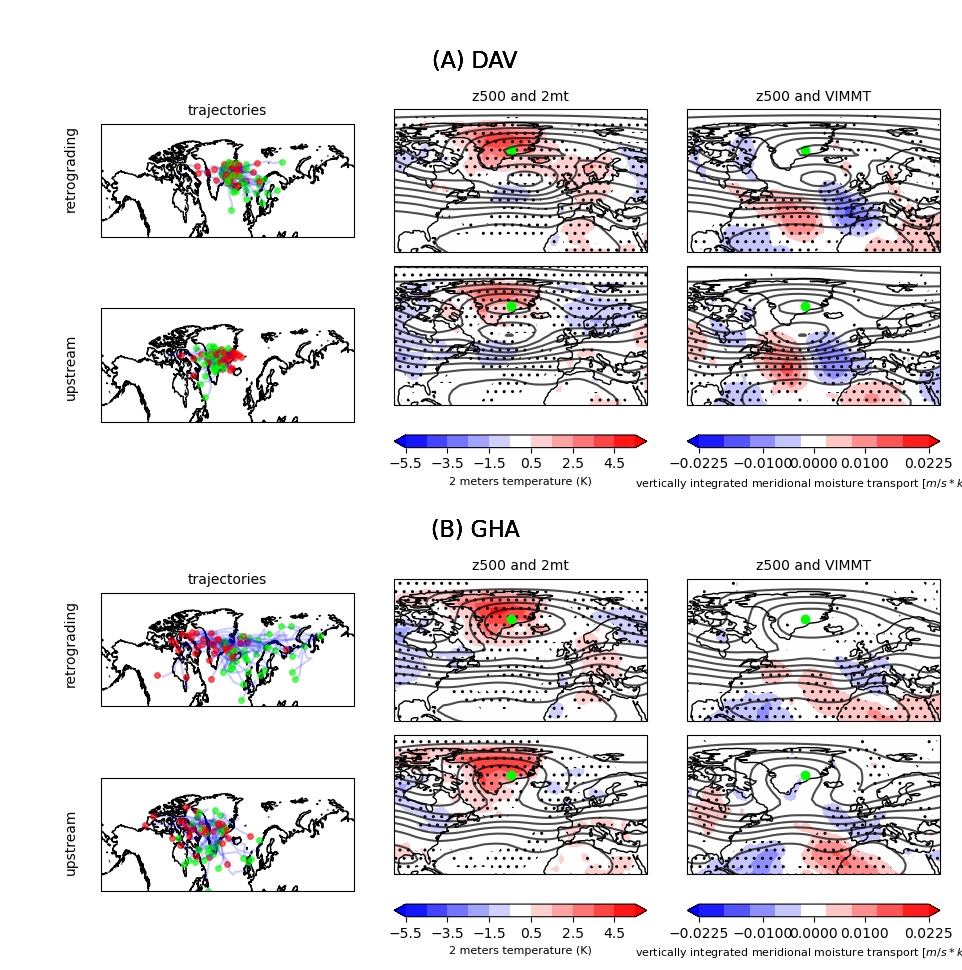

In [14]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 10
colorbar_fontsize = 8
small_titles = ['trajectories', 'z500 and 2mt', 'z500 and VIMMT']

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.2,1,1,1],height_ratios=[0.6,1, 1.4, 0.6, 1, 1.4], hspace=0.1)
lon = ds_filt_DAV['lon']
lon_IVT = ds_IVT['x']*2.5 - 180
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 20, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4640,6000,50)
t2m_range = np.arange(-5.5,5.6,1)
IVT_range = np.arange(-0.0225, 0.023, 0.005)
IVT_ticks = (-0.0225,-0.01,int(0),0.01,0.0225)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            ax.plot(plon,
                       plat,
                       marker='o',
                       color='lime',
                       transform=ccrs.PlateCarree())
            if (j-1)%3 == 0:
                ax.set_title(small_titles[i-1],fontsize=small_titles_fontsize)
            'TRAJECTORIES'
            'retrograding'
            if i == 1 and (j-1)%3==0:
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                k = int((j-1)/3)
                for l,label in enumerate(labels_retrograding[k]):
                    cm = ax.plot(dics[k][label]['track'][1],dics[k][label]['track'][0],color='blue',alpha=0.2,transform=datacrs)
                    #plot the ending center of mass position
                    end = ax.plot(dics[k][label]['track'][1][-1],dics[k][label]['track'][0][-1],'o', markersize=4,color='r',alpha=0.6,transform=datacrs)
                    #plot the starting center of mass position
                    start = ax.plot(dics[k][label]['track'][1][0],dics[k][label]['track'][0][0],'o', markersize=4,color='lime',alpha=0.6,transform=datacrs)
            'upstream'
            if i == 1 and (j-2)%3==0:
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                k = int((j-2)/3)
                for l,label in enumerate(labels_upstream[k]):
                    cm = ax.plot(dics[k][label]['track'][1],dics[k][label]['track'][0],color='blue',alpha=0.2,transform=datacrs)
                    #plot the ending center of mass position
                    end = ax.plot(dics[k][label]['track'][1][-1],dics[k][label]['track'][0][-1],'o', markersize=4,color='r',alpha=0.6,transform=datacrs)
                    #plot the starting center of mass position
                    start = ax.plot(dics[k][label]['track'][1][0],dics[k][label]['track'][0][0],'o', markersize=4,color='lime',alpha=0.6,transform=datacrs)

            'COMPOSITES'
            't2m'
            if i == 2 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(lon,lat,zg_retrograding_comp[k],z_levels,alpha = alpha_cont,colors='black')
                shad_t2m = plt.contourf(lon,lat,t2m_retrograding_comp[k], cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(lon, lat,t2m_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 2 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(lon,lat,zg_upstream_comp[k],z_levels,alpha = alpha_cont,colors='black')
                shad_t2m = plt.contourf(lon,lat,t2m_upstream_comp[k],cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(lon, lat,t2m_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.']) 
                cb = fig.colorbar(shad_t2m, orientation='horizontal')
                cb.set_label('2 meters temperature (K)',size=colorbar_fontsize)

            'IVT'    
            if i == 3 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(lon,lat,zg_retrograding_comp[k],z_levels,alpha = alpha_cont,colors='black')
                shad_IVT = plt.contourf(lon_IVT,lat,IVT_retrograding_comp[k],cmap='bwr',levels=IVT_range,extend='both')
                hatchings = ax.contourf(lon_IVT, lat,IVT_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 3 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(lon,lat,zg_upstream_comp[k],z_levels,alpha = alpha_cont,colors='black')
                shad_IVT = plt.contourf(lon_IVT,lat,IVT_upstream_comp[k],cmap='bwr',levels=IVT_range,extend='both')
                hatchings = ax.contourf(lon_IVT, lat,IVT_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])
                cb = fig.colorbar(shad_IVT, orientation='horizontal',ticks=IVT_ticks)
                cb.set_label('vertically integrated meridional moisture transport [$m/s * kg/kg$]',size=colorbar_fontsize)
        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(A) DAV' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(B) GHA' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 6:
                middle_ax.text(0.5, 0.4, '(C) MIX' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

#plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure2.pdf')

In [15]:
print(labels_upstream[1],len(labels_upstream[1]))

[np.int64(107), np.int64(188), np.int64(227), np.int64(241), np.int64(289), np.int64(1167), np.int64(1211), np.int64(1400), np.int64(1452), np.int64(1715), np.int64(1752), np.int64(1933), np.int64(2029), np.int64(2062), np.int64(2194), np.int64(2232), np.int64(2594), np.int64(2803), np.int64(2883), np.int64(2926), np.int64(2934), np.int64(3022), np.int64(3111), np.int64(3145), np.int64(3197), np.int64(3237), np.int64(3273), np.int64(3618), np.int64(3627)] 29


In [16]:
print(labels_retrograding[1],len(labels_retrograding[1]))

[np.int64(99), np.int64(230), np.int64(324), np.int64(331), np.int64(450), np.int64(485), np.int64(541), np.int64(653), np.int64(731), np.int64(778), np.int64(821), np.int64(829), np.int64(1308), np.int64(1341), np.int64(1343), np.int64(1625), np.int64(1842), np.int64(1851), np.int64(1930), np.int64(2141), np.int64(2240), np.int64(2450), np.int64(2515), np.int64(2592), np.int64(2645), np.int64(2769), np.int64(2810), np.int64(2841), np.int64(2980), np.int64(3104), np.int64(3156), np.int64(3316), np.int64(3352), np.int64(3386), np.int64(3438), np.int64(3534)] 36


# FIGURE 3

## Boxplots

In [17]:
areas_retrograding = [[],[],[]]
persistences_retrograding = [[],[],[]]
intensities_retrograding = [[],[],[]]
areas_upstream = [[],[],[]]
persistences_upstream = [[],[],[]]
intensities_upstream = [[],[],[]]
for i in range(3):
    for l in labels_retrograding[i]:
        areas_retrograding[i].append(np.mean(dics[i][l]['area']))
        persistences_retrograding[i].append(dics[i][l]['persistence'])
        intensities_retrograding[i].append(np.mean(dics[i][l]['intensity'])/np.mean(dics[i][l]['area']))
    for l in labels_upstream[i]:
        areas_upstream[i].append(np.mean(dics[i][l]['area']))
        persistences_upstream[i].append(dics[i][l]['persistence'])
        intensities_upstream[i].append(np.mean(dics[i][l]['intensity'])/np.mean(dics[i][l]['area']))

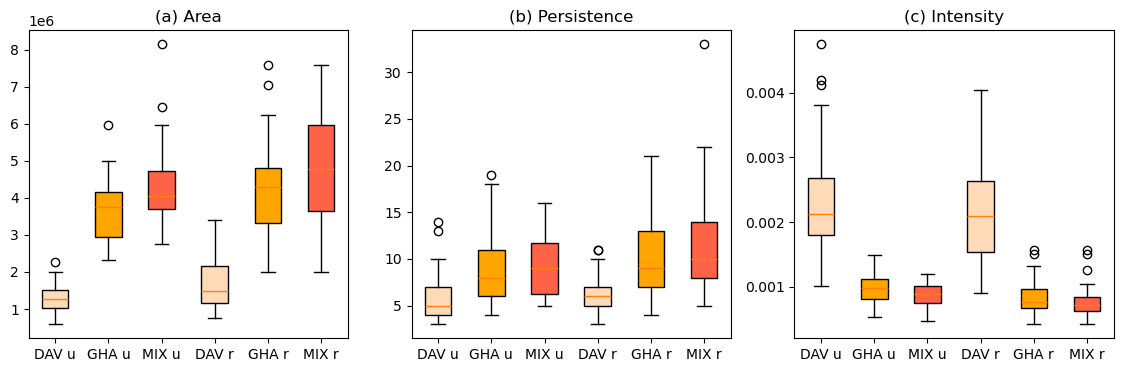

In [18]:
#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(14, 4))

axs[0].set_title('(a) Area')
areas = areas_upstream + areas_retrograding
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[0].set_xticklabels(['DAV u', 'GHA u', 'MIX u','DAV r', 'GHA r', 'MIX r'])
colors = ['peachpuff', 'orange', 'tomato','peachpuff', 'orange', 'tomato']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
persistences = persistences_upstream + persistences_retrograding
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True)
axs[1].set_xticklabels(['DAV u', 'GHA u', 'MIX u','DAV r', 'GHA r', 'MIX r'])
colors = ['peachpuff', 'orange', 'tomato','peachpuff', 'orange', 'tomato']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[2].set_title('(c) Intensity')
intensities = intensities_upstream + intensities_retrograding
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True)
axs[2].set_xticklabels(['DAV u', 'GHA u', 'MIX u','DAV r', 'GHA r', 'MIX r'])
colors = ['peachpuff', 'orange', 'tomato','peachpuff', 'orange', 'tomato']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

# FIGURE 4

## Frequency

In [19]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [31]:
count_DAV = np.zeros((3))
count_GHA = np.zeros((3))
count_MIX = np.zeros((3))
list_DAV = np.zeros(times.shape)
list_DAV_upstream = np.zeros(times.shape)
list_DAV_retrograding = np.zeros(times.shape)
list_GHA = np.zeros(times.shape)
list_GHA_upstream = np.zeros(times.shape)
list_GHA_retrograding = np.zeros(times.shape)
count_m = 0
freq_per_month_DAV = [[],[],[]]#np.zeros((2,len(times)))
freq_per_month_GHA = [[],[],[]]#np.zeros((2,len(times)))
freq_per_month_MIX = [[],[],[]]#np.zeros((2,len(times)))
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
check=0
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    MIX_gr = MIX_filt.values[t,mask_bool]
    #print(DAV_gr)
    month = str(time.values)[5:7]
    if month in months:
        '''
        #method1
        count_m += mask_size
        count_DAV += np.sum(DAV_gr,axis=(0))
        count_GHA += np.sum(GHA_gr,axis=(0))
        count_MIX += np.sum(MIX_gr,axis=(0))
        '''
        '''
        #method2
        count_m += 1
        count_DAV += np.any(DAV_gr>0)
        count_GHA += np.any(GHA_gr>0)
        count_MIX += np.any(MIX_gr>0)
        '''
        #method3
        count_m += 1
        threshold = 0.2
        for l in np.unique(DAV_gr):
            if l != 0 and np.sum(DAV_gr==l) > threshold*mask_size/2:
                count_DAV[0] += 1
                list_DAV[t] = 1
            if l != 0 and dics[0][l]['track'][1][0]>plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                count_DAV[1] += 1
                list_DAV_retrograding[t] = 1
            if l != 0 and dics[0][l]['track'][1][0]<=plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                count_DAV[2] += 1
                list_DAV_upstream[t] = 1
        for l in np.unique(GHA_gr):
            if l != 0 and np.sum(GHA_gr==l) > threshold*mask_size/2:
                count_GHA[0] += 1
                list_DAV[t] = 1
            if l != 0 and dics[1][l]['track'][1][0]>plon and np.sum(GHA_gr==l) > threshold*mask_size/2:
                count_GHA[1] += 1
                list_GHA_retrograding[t] = 1
            if l != 0 and dics[1][l]['track'][1][0]>plon and np.sum(GHA_gr==l) > threshold*mask_size/2:
                count_GHA[2] += 1
                list_GHA_upstream[t] = 1
        for l in np.unique(MIX_gr):
            if l != 0 and np.sum(MIX_gr==l) > threshold*mask_size/2:
                count_MIX[0] += 1
            if l != 0 and np.mean(dics[2][l]['track'][1])>plon and np.sum(MIX_gr==l) > threshold*mask_size/2:
                count_MIX[1] += 1
            if l != 0 and np.mean(dics[2][l]['track'][1])<=plon and np.sum(MIX_gr==l) > threshold*mask_size/2:
                count_MIX[2] += 1

        if month != tmp:
            #print(count_m)
            #print(count)

            check += 1
            tmp = month
            freq_per_month_DAV[0].append(count_DAV[0]*100/count_m)
            freq_per_month_GHA[0].append(count_GHA[0]*100/count_m)
            freq_per_month_MIX[0].append(count_MIX[0]*100/count_m)
            freq_per_month_DAV[1].append(count_DAV[1]*100/count_m)
            freq_per_month_GHA[1].append(count_GHA[1]*100/count_m)
            freq_per_month_MIX[1].append(count_MIX[1]*100/count_m)
            freq_per_month_DAV[2].append(count_DAV[2]*100/count_m)
            freq_per_month_GHA[2].append(count_GHA[2]*100/count_m)
            freq_per_month_MIX[2].append(count_MIX[2]*100/count_m)
            count_DAV = np.zeros((3))
            count_GHA = np.zeros((3))
            count_MIX = np.zeros((3))
            count_m = 0

print(check)

30681it [00:19, 1576.41it/s]

251


0
1
2


Text(0.5, 0.98, '')

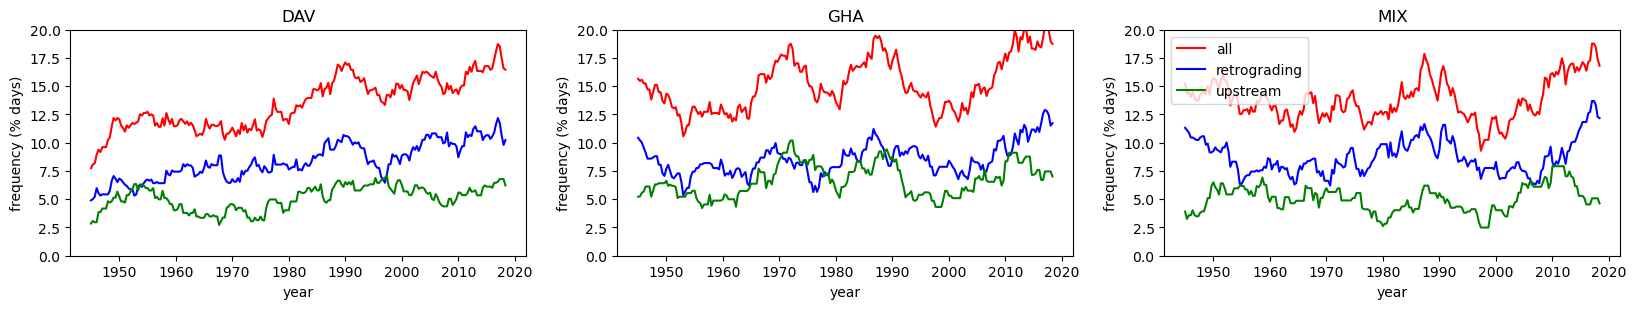

In [21]:
window = 10*len(months)
years = np.arange(1940,2024,1)
months_list = np.arange(0,len(freq_per_month_DAV[0]),1)
months_run_avg = months_list[int(window/2):int(-window/2)]
years_run_avg = []
for month in months_run_avg:
    years_run_avg.append(month/3 + 1940)

titles = ['DAV','GHA','MIX']
freqs = [freq_per_month_DAV,freq_per_month_GHA,freq_per_month_MIX]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
for i in range(3):

    print(i)
    #axes[0].plot(months_list,freq_per_month_DAV,color='black',label='freq. per month')
    axes[i].plot(years_run_avg,running_mean(freqs[i][0],window),color='r',label='all')
    axes[i].set_title(titles[i])
    axes[i].set_ylim((0,20))
    axes[i].set_aspect(600)
    #axes[0][i].legend()
    
    #axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
    axes[i].plot(years_run_avg,running_mean(freqs[i][1],window),color='b',label='retrograding')
    axes[i].set_ylim((0,20))
    axes[i].set_aspect(600)
    
    #axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
    axes[i].plot(years_run_avg,running_mean(freqs[i][2],window),color='g',label='upstream')
    axes[i].set_ylim((0,20))
    axes[i].set_aspect(600)

    axes[i].set_xlabel('year')
    axes[i].set_ylabel('frequency (% days)')

    axes[i].set_aspect(2)


plt.legend()
    
fig.suptitle('', fontsize=20)


In [22]:
# SAVING THE DATA
import pandas as pd

data_arrays_freq_DAV = []

for block_freq in freq_per_month_DAV:
    # Define a time range
    date_range = pd.date_range(str(ds_filt_DAV['time'][0].values),periods=len(block_freq)/3*12-1, freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]

    # Create the DataArray
    data_array = xr.DataArray(
    data=np.array(block_freq),  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="all",  # Optional: Name of the DataArray
    attrs={"description": "A DataArray with only a time dimension"}  # Optional: Attributes
    )

    data_arrays_freq_DAV.append(data_array)

ds = data_arrays_freq_DAV[0].to_dataset()
ds['retrograding'] = data_arrays_freq_DAV[1]
ds['upstream'] = data_arrays_freq_DAV[2]

ds.to_netcdf('/emmy-noether/home/mf671/github/greenland_blocking/article_plots_2.0/Part2_DATA/ERA5_frequencies.nc')

/tmp/ipykernel_264040/2274935197.py:8: FutureWarning: Non-integer 'periods' in pd.date_range, pd.timedelta_range, pd.period_range, and pd.interval_range are deprecated and will raise in a future version.
  date_range = pd.date_range(str(ds_filt_DAV['time'][0].values),periods=len(block_freq)/3*12-1, freq="ME")


## Correlation Coefficients

In [27]:
list_DAV_upstream = np.zeros(time.shape)
list_DAV_retrograding = np.zeros(time.shape)
list_GHA_upstream = np.zeros(time.shape)
list_GHA_retrograding = np.zeros(time.shape)

In [ ]:
for i,elmnt in enumerate(DAV_gr):
    if elmnt